# Análise de Viagens a Serviço — Governo Federal (2025)

## Projeto Avaliativo — Análise de Dados com Python

### Objetivo

Analisar dados públicos de viagens a serviço do Governo Federal
referentes ao ano de 2025, utilizando Python, PostgreSQL e técnicas
de análise e visualização de dados.

### Arquitetura do projeto

O processamento dos dados segue três camadas:

- **Raw:** armazenamento dos dados originais extraídos dos arquivos CSV.
- **Silver:** dados tratados, tipados e organizados com regras de integridade.
- **Gold:** dados agregados para responder às perguntas de negócio.

### Ferramentas utilizadas

- Python
- PostgreSQL
- pandas
- Matplotlib
- Jupyter Notebook

### Etapas da análise

1. Verificação dos dados disponíveis.
2. Criação da camada Gold.
3. Resolução das sete perguntas de negócio.
4. Construção de gráficos.
5. Interpretação dos resultados.

In [1]:
import sys

print("Python em uso:", sys.executable)
print("Ambiente virtual configurado com sucesso!")

Python em uso: c:\Users\gatsu\Documents\projetos\sctec.tad\Projeto_Final_CaioCorrea_Analise_de_Dados_T5\.venv\Scripts\python.exe
Ambiente virtual configurado com sucesso!


In [2]:
from banco import conectar

with conectar() as conexao, conexao.cursor() as cursor:
    cursor.execute("SELECT current_database(), version()")
    resultado = cursor.fetchone()

print("Banco conectado:", resultado[0])
print("PostgreSQL:", resultado[1].split(",")[0])

Banco conectado: transparencia
PostgreSQL: PostgreSQL 18.6 on x86_64-windows


In [3]:
import pandas as pd

consulta = """
SELECT 'Viagens' AS tabela, COUNT(*) AS registros
FROM silver_viagem

UNION ALL

SELECT 'Pagamentos', COUNT(*)
FROM silver_pagamento

UNION ALL

SELECT 'Passagens', COUNT(*)
FROM silver_passagem

UNION ALL

SELECT 'Trechos', COUNT(*)
FROM silver_trecho;
"""

with conectar() as conexao, conexao.cursor() as cursor:
    cursor.execute(consulta)
    dados = cursor.fetchall()
    colunas = [coluna[0] for coluna in cursor.description]

resumo_silver = pd.DataFrame(dados, columns=colunas)

display(resumo_silver)

,tabela,registros
0,Passagens,167260
1,Viagens,341860
2,Pagamentos,606916
3,Trechos,763349


## Pergunta 1 — Quais são os cinco órgãos com maior gasto total em viagens?

Nesta análise, identificamos os cinco órgãos superiores com os maiores
gastos em viagens a serviço durante 2025.

Os valores são obtidos da tabela `silver_viagem`, agrupados por órgão
superior e ordenados pelo gasto total em ordem decrescente.

In [4]:
consulta_1 = """
SELECT
    nome_orgao_superior AS orgao,
    COUNT(*) AS quantidade_viagens,
    SUM(valor_total) AS gasto_total
FROM silver_viagem
GROUP BY nome_orgao_superior
ORDER BY gasto_total DESC
LIMIT 5;
"""

with conectar() as conexao, conexao.cursor() as cursor:
    cursor.execute(consulta_1)
    resultados = cursor.fetchall()
    colunas = [coluna[0] for coluna in cursor.description]

top_5_orgaos = pd.DataFrame(resultados, columns=colunas)

display(top_5_orgaos)

,orgao,quantidade_viagens,gasto_total
0,Ministério da Justiça e Segurança Pública,75742,486933121.65
1,Ministério da Defesa,61912,156070304.49
2,Ministério da Educação,65295,111291349.34
3,Ministério do Meio Ambiente e Mudança do Clima,19413,49697710.16
4,Ministério da Previdência Social,8190,40417309.06


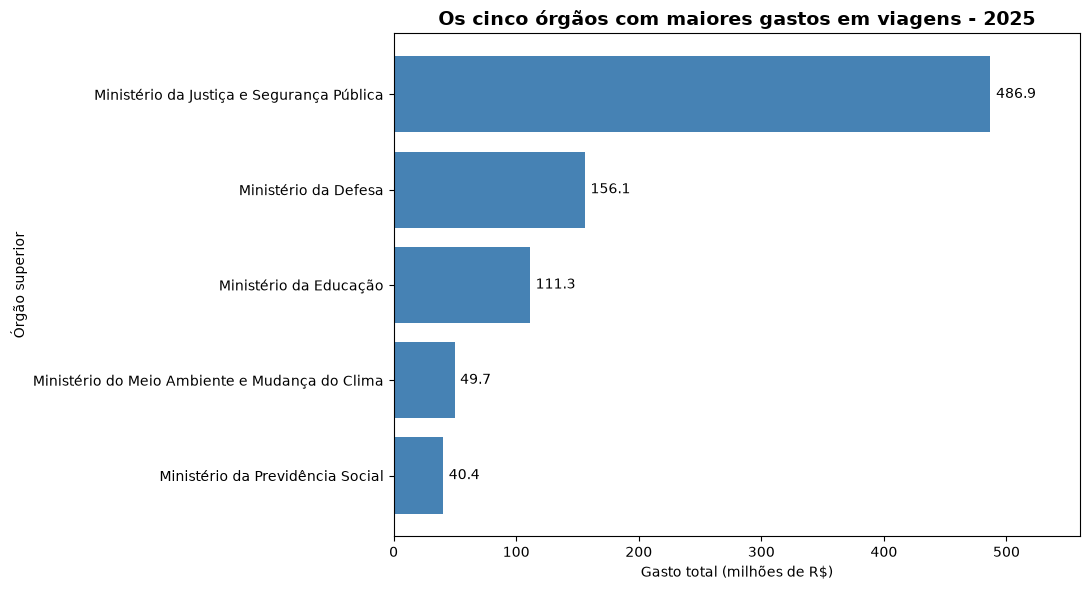

In [5]:
import matplotlib.pyplot as plt

# Preparar os valores para visualizacao em milhoes de reais.
dados_grafico = top_5_orgaos.copy()
dados_grafico["gasto_milhoes"] = (
    dados_grafico["gasto_total"].astype(float) / 1_000_000
)

# Criar o grafico.
fig, ax = plt.subplots(figsize=(11, 6))

barras = ax.barh(
    dados_grafico["orgao"],
    dados_grafico["gasto_milhoes"],
    color="steelblue",
)

# Exibir o maior gasto na parte superior.
ax.invert_yaxis()

# Configurar titulo e eixos.
ax.set_title(
    "Os cinco órgãos com maiores gastos em viagens - 2025",
    fontsize=14,
    fontweight="bold",
)

ax.set_xlabel("Gasto total (milhões de R$)")
ax.set_ylabel("Órgão superior")

# Exibir os valores ao lado das barras.
ax.bar_label(
    barras,
    fmt="%.1f",
    padding=4,
)

ax.set_xlim(0, dados_grafico["gasto_milhoes"].max() * 1.15)

plt.tight_layout()
plt.show()

### Interpretação dos resultados

O Ministério da Justiça e Segurança Pública apresentou o maior gasto
total em viagens a serviço em 2025, com aproximadamente R$ 486,9 milhões.

O Ministério da Defesa ficou na segunda posição, com R$ 156,1 milhões,
seguido pelo Ministério da Educação, com R$ 111,3 milhões.

O gasto do Ministério da Justiça e Segurança Pública foi aproximadamente
3,1 vezes superior ao do Ministério da Defesa.

Os resultados demonstram uma concentração dos gastos em determinados
órgãos federais. Entretanto, os valores isolados não permitem avaliar
a eficiência dessas despesas, pois seria necessário considerar as
atribuições e necessidades operacionais de cada órgão.

## Pergunta 2 — Quais são os três destinos com maior custo médio de viagem?

Esta análise identifica os três destinos registrados com maior custo
médio de viagem em 2025.

O custo médio é calculado dividindo o gasto total pela quantidade de
viagens associadas a cada destino.

**Critério:** o campo `destinos` é analisado conforme registrado na
base de dados, sem separar viagens com múltiplas localidades.

In [6]:
consulta_2 = """
SELECT
    destinos AS destino,
    COUNT(*) AS quantidade_viagens,
    ROUND(AVG(valor_total), 2) AS custo_medio
FROM silver_viagem
WHERE destinos IS NOT NULL
  AND TRIM(destinos) <> ''
GROUP BY destinos
ORDER BY custo_medio DESC
LIMIT 3;
"""

with conectar() as conexao, conexao.cursor() as cursor:
    cursor.execute(consulta_2)
    resultados = cursor.fetchall()
    colunas = [coluna[0] for coluna in cursor.description]

top_3_destinos = pd.DataFrame(resultados, columns=colunas)

display(top_3_destinos)

,destino,quantidade_viagens,custo_medio
0,"Abu Dabi/Emirados Árabes, Riad/Arábia Saudita,...",1,245852.80
1,"Brasília/DF, Rio Branco/AC, Cruzeiro do Sul/AC...",1,216729.36
2,"Brasília/DF, Rio de Janeiro/RJ, Angra dos Reis...",1,207220.14


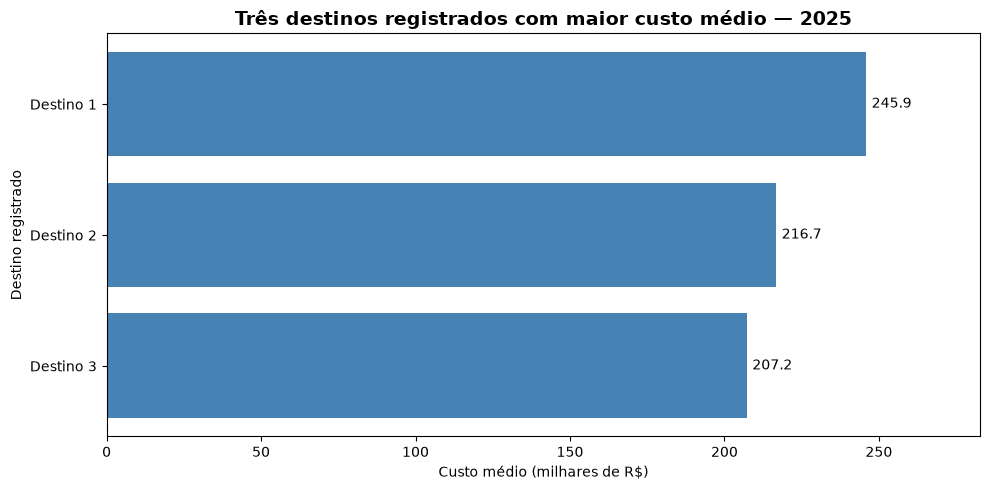

In [7]:
# Preparar os dados para o gráfico.
dados_destinos = top_3_destinos.copy()

dados_destinos["custo_medio"] = dados_destinos["custo_medio"].astype(float)

# Utilizar identificadores curtos para facilitar a leitura.
dados_destinos["identificador"] = [
    f"Destino {i + 1}" for i in range(len(dados_destinos))
]

# Criar o gráfico.
fig, ax = plt.subplots(figsize=(10, 5))

barras = ax.barh(
    dados_destinos["identificador"],
    dados_destinos["custo_medio"] / 1_000,
    color="steelblue",
)

ax.invert_yaxis()

ax.set_title(
    "Três destinos registrados com maior custo médio — 2025",
    fontsize=14,
    fontweight="bold",
)

ax.set_xlabel("Custo médio (milhares de R$)")
ax.set_ylabel("Destino registrado")

ax.bar_label(barras, fmt="%.1f", padding=4)

ax.set_xlim(0, dados_destinos["custo_medio"].max() / 1_000 * 1.15)

plt.tight_layout()
plt.show()

### Interpretação dos resultados

A análise identificou os três itinerários registrados com os maiores
custos médios de viagem em 2025.

O primeiro apresentou custo médio de aproximadamente R$ 245,9 mil,
seguido pelo segundo, com R$ 216,7 mil, e pelo terceiro, com R$ 207,2 mil.

Entretanto, cada um desses itinerários possui apenas uma viagem
registrada. Portanto, nesses casos, o custo médio corresponde ao
valor total de uma única viagem.

Além disso, o campo `destinos` pode conter múltiplas localidades,
representando um itinerário completo, e não uma cidade isolada.

Assim, os resultados identificam os itinerários de maior custo médio
na base, mas não permitem concluir quais cidades apresentam,
de maneira geral, os maiores custos de viagem.

## Pergunta 3 — Qual foi a viagem de maior duração e quanto ela custou?

Esta análise identifica a viagem com maior duração registrada na base
de dados de 2025.

A duração é calculada considerando a diferença entre a data de término
e a data de início, incluindo ambos os dias.

Também são apresentados o órgão responsável, o viajante, o destino
registrado e o custo total da viagem.

In [8]:
consulta_3 = """
SELECT
    id_viagem,
    nome_orgao_superior AS orgao,
    nome_viajante AS viajante,
    destinos AS destino,
    data_inicio,
    data_fim,
    duracao_dias,
    valor_total AS custo_total
FROM silver_viagem
WHERE duracao_dias IS NOT NULL
ORDER BY duracao_dias DESC, valor_total DESC, id_viagem
LIMIT 1;
"""

with conectar() as conexao, conexao.cursor() as cursor:
    cursor.execute(consulta_3)
    resultados = cursor.fetchall()
    colunas = [coluna[0] for coluna in cursor.description]

viagem_mais_longa = pd.DataFrame(resultados, columns=colunas)

display(viagem_mais_longa)

,id_viagem,orgao,viajante,destino,data_inicio,data_fim,duracao_dias,custo_total
0,0000000000020699856,Ministério da Previdência Social,LUISANGELA CORREA FRANCO DE FARIA,Mogi Mirim/SP,2025-01-13,2026-01-31,384,0.00


### Interpretação dos resultados

A viagem de maior duração identificada na base de dados de 2025
foi registrada pelo Ministério da Previdência Social, com destino
a Mogi Mirim/SP.

O período informado compreende 13 de janeiro de 2025 a
31 de janeiro de 2026, totalizando 384 dias, considerando
as datas inicial e final.

Apesar da duração elevada, o custo total registrado na camada
Silver foi de R$ 0,00.

O resultado demonstra que a duração de uma viagem não está
necessariamente associada a um gasto elevado nos registros
analisados.

Além disso, a viagem ultrapassa o ano de 2025, indicando que
a base pode conter deslocamentos com término no ano seguinte.

O valor zero deve ser interpretado como ausência de gastos
registrados nos campos utilizados no cálculo, e não como
comprovação de que não houve despesas relacionadas à viagem.

## Pergunta 4 — Qual tipo de pagamento apresenta o maior valor médio?

Esta análise compara os valores médios dos diferentes tipos de pagamento
registrados nas viagens a serviço em 2025.

Para cada modalidade, são apresentados a quantidade de pagamentos,
o valor médio e o valor total movimentado.

O cálculo considera os registros individuais da tabela `silver_pagamento`.

In [9]:
consulta_4 = """
SELECT
    tipo_pagamento,
    COUNT(*) AS quantidade_pagamentos,
    ROUND(AVG(valor), 2) AS valor_medio,
    ROUND(SUM(valor), 2) AS valor_total
FROM silver_pagamento
WHERE tipo_pagamento IS NOT NULL
GROUP BY tipo_pagamento
ORDER BY valor_medio DESC;
"""

with conectar() as conexao, conexao.cursor() as cursor:
    cursor.execute(consulta_4)
    resultados = cursor.fetchall()
    colunas = [coluna[0] for coluna in cursor.description]

media_por_pagamento = pd.DataFrame(resultados, columns=colunas)

display(media_por_pagamento)

,tipo_pagamento,quantidade_pagamentos,valor_medio,valor_total
0,DIÁRIAS,401463,2078.28,834352643.52
1,PASSAGEM,188985,1878.34,354978915.13
2,Serviço correlato: seguro,4894,447.51,2190136.71
3,RESTITUIÇÃO,11574,245.70,2843762.01


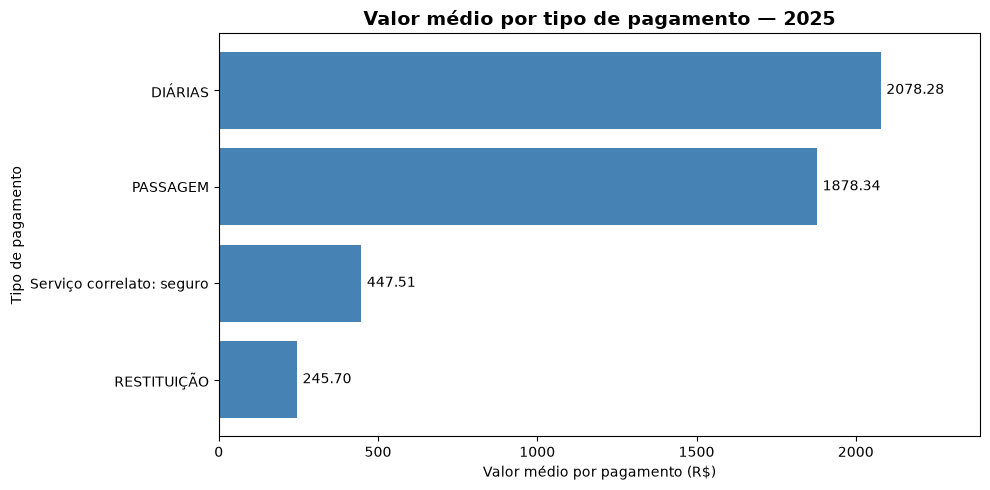

In [10]:
# Preparar os dados para o gráfico.
dados_pagamentos = media_por_pagamento.copy()
dados_pagamentos["valor_medio"] = dados_pagamentos["valor_medio"].astype(float)

# Criar o gráfico.
fig, ax = plt.subplots(figsize=(10, 5))

barras = ax.barh(
    dados_pagamentos["tipo_pagamento"],
    dados_pagamentos["valor_medio"],
    color="steelblue",
)

# Apresentar o maior valor na parte superior.
ax.invert_yaxis()

# Configurar título e eixos.
ax.set_title(
    "Valor médio por tipo de pagamento — 2025",
    fontsize=14,
    fontweight="bold",
)

ax.set_xlabel("Valor médio por pagamento (R$)")
ax.set_ylabel("Tipo de pagamento")

# Apresentar os valores ao lado das barras.
ax.bar_label(barras, fmt="%.2f", padding=4)

ax.set_xlim(0, dados_pagamentos["valor_medio"].max() * 1.15)

plt.tight_layout()
plt.show()

### Interpretação dos resultados

A análise dos pagamentos relacionados às viagens a serviço em 2025
identificou que a modalidade DIÁRIAS apresentou o maior valor médio
por pagamento, aproximadamente R$ 2.078,28, considerando 401.463 registros.

A modalidade PASSAGEM ficou na segunda posição, com valor médio de
R$ 1.878,34 e 188.985 registros.

Os pagamentos classificados como Serviço correlato: seguro apresentaram
média de R$ 447,51, enquanto a modalidade RESTITUIÇÃO registrou
o menor valor médio, de R$ 245,70.

Os resultados demonstram diferenças entre os valores médios das
modalidades. Entretanto, é importante observar que a análise considera
pagamentos individuais, e não o custo médio total de cada viagem.

Além disso, o valor médio não representa necessariamente o custo
mais frequente, pois pagamentos de valores elevados podem influenciar
a média.

## Pergunta 5 — Qual é o meio de transporte mais utilizado nos trechos?

Esta análise identifica os meios de transporte mais frequentes nos
trechos das viagens a serviço em 2025.

A contagem considera os registros individuais da tabela `silver_trecho`,
e não a quantidade de viagens distintas.

Uma mesma viagem pode conter vários trechos e utilizar diferentes
meios de transporte.

In [11]:
consulta_5 = """
SELECT
    meio_transporte,
    COUNT(*) AS quantidade_trechos
FROM silver_trecho
WHERE meio_transporte IS NOT NULL
  AND TRIM(meio_transporte) <> ''
GROUP BY meio_transporte
ORDER BY quantidade_trechos DESC, meio_transporte;
"""

with conectar() as conexao, conexao.cursor() as cursor:
    cursor.execute(consulta_5)
    resultados = cursor.fetchall()
    colunas = [coluna[0] for coluna in cursor.description]

transportes_frequentes = pd.DataFrame(resultados, columns=colunas)

display(transportes_frequentes)

,meio_transporte,quantidade_trechos
0,Veículo Oficial,386424
1,Aéreo,232666
2,Rodoviário,64970
3,Veículo Próprio,42846
4,Inválido,26659
5,Fluvial,8429
6,Ferroviário,874
7,Marítimo,481


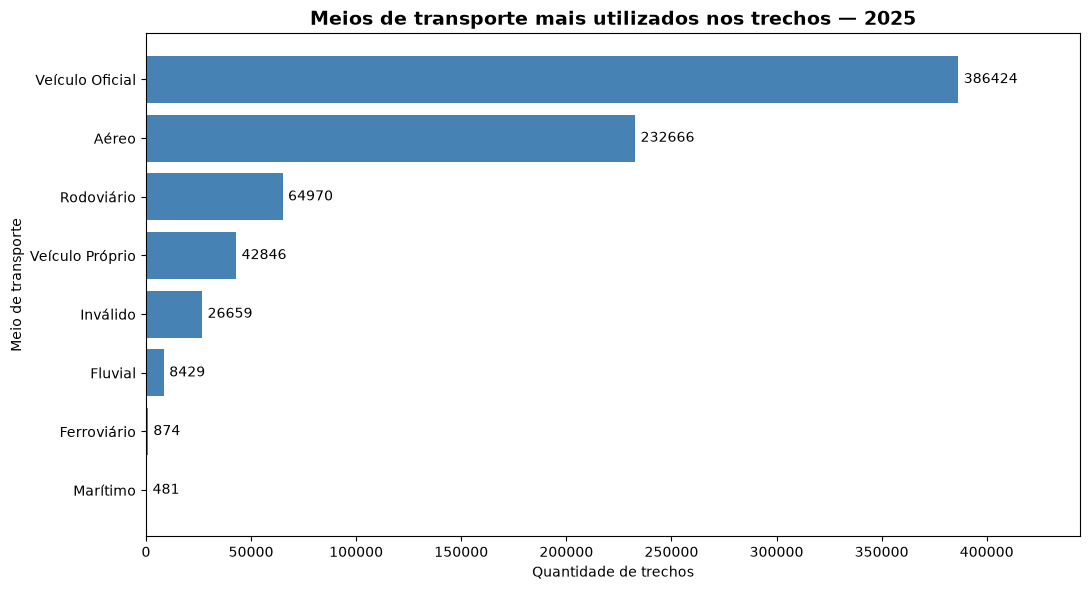

In [12]:
# Preparar os dados para o gráfico.
dados_transportes = transportes_frequentes.copy()

# Criar o gráfico.
fig, ax = plt.subplots(figsize=(11, 6))

barras = ax.barh(
    dados_transportes["meio_transporte"],
    dados_transportes["quantidade_trechos"],
    color="steelblue",
)

# Apresentar a categoria mais frequente na parte superior.
ax.invert_yaxis()

# Configurar título e eixos.
ax.set_title(
    "Meios de transporte mais utilizados nos trechos — 2025",
    fontsize=14,
    fontweight="bold",
)

ax.set_xlabel("Quantidade de trechos")
ax.set_ylabel("Meio de transporte")

# Exibir os valores ao lado das barras.
ax.bar_label(barras, fmt="%d", padding=4)

ax.set_xlim(
    0,
    dados_transportes["quantidade_trechos"].max() * 1.15,
)

plt.tight_layout()
plt.show()

### Interpretação dos resultados

A análise dos meios de transporte utilizados nos trechos das viagens
a serviço em 2025 identificou que a modalidade Veículo Oficial
foi a mais frequente, com 386.424 registros.

O transporte Aéreo apareceu na segunda posição, com 232.666 trechos,
seguido pelo Rodoviário, com 64.970 registros, e pelo Veículo Próprio,
com 42.846.

Também foram identificados 26.659 registros classificados como
"Inválido". Essa categoria indica uma limitação na qualidade dos dados,
pois não permite identificar o meio de transporte efetivamente utilizado.

As modalidades Fluvial, Ferroviário e Marítimo apresentaram frequências
consideravelmente menores.

É importante destacar que a análise considera a quantidade de trechos,
e não o número de viagens ou de viajantes. Uma mesma viagem pode conter
vários deslocamentos, inclusive utilizando diferentes meios de transporte.

## Pergunta 6 — Qual é a UF de destino mais frequente nos trechos?

Esta análise identifica as Unidades da Federação (UFs) mais frequentes
como destino nos trechos das viagens a serviço em 2025.

Os dados são obtidos da tabela `silver_trecho`, utilizando o campo
`destino_uf`.

A contagem considera os registros individuais de trechos, e não
a quantidade de viagens distintas.

Valores nulos ou vazios são desconsiderados nesta análise.

In [13]:
consulta_6 = """
SELECT
    destino_uf AS uf_destino,
    COUNT(*) AS quantidade_trechos
FROM silver_trecho
WHERE destino_uf IS NOT NULL
  AND TRIM(destino_uf) <> ''
GROUP BY destino_uf
ORDER BY quantidade_trechos DESC, destino_uf;
"""

with conectar() as conexao, conexao.cursor() as cursor:
    cursor.execute(consulta_6)
    resultados = cursor.fetchall()
    colunas = [coluna[0] for coluna in cursor.description]

ufs_destino_frequentes = pd.DataFrame(resultados, columns=colunas)

display(ufs_destino_frequentes)

,uf_destino,quantidade_trechos
0,São Paulo,82722
1,Distrito Federal,79962
2,Minas Gerais,50965
3,Rio de Janeiro,44197
4,Paraná,42603
5,Pará,40044
6,Rio Grande do Sul,38684
7,Mato Grosso do Sul,30516
8,Bahia,28375
9,Pernambuco,28372


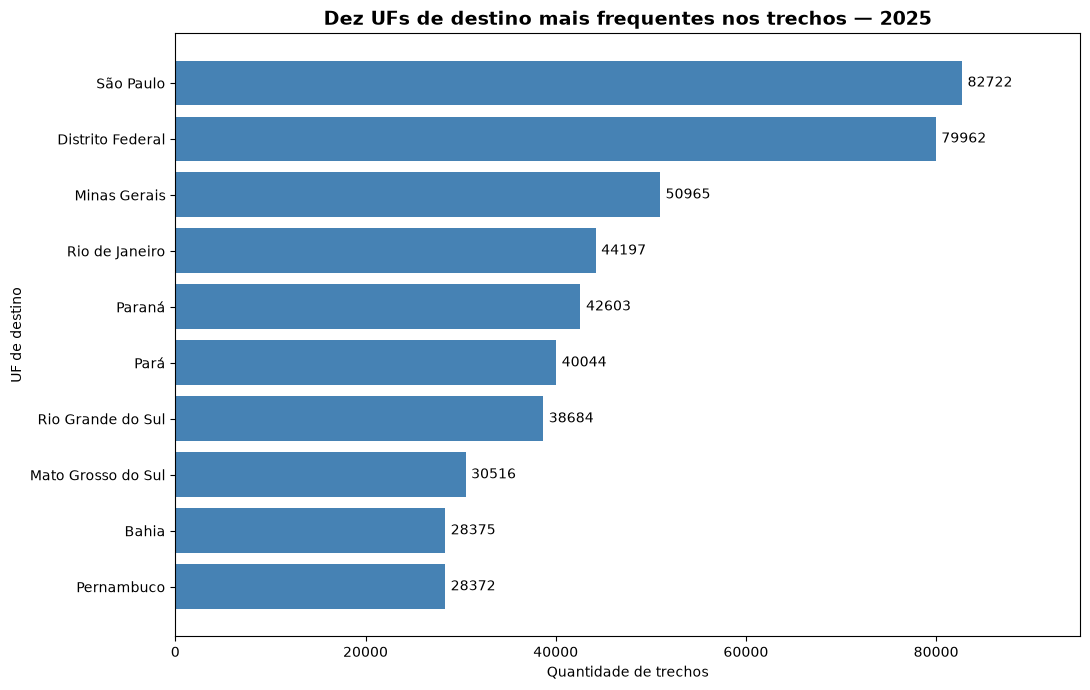

In [14]:
# Selecionar as dez UFs com maior quantidade de trechos.
top_10_ufs = ufs_destino_frequentes.head(10).copy()

# Criar o gráfico.
fig, ax = plt.subplots(figsize=(11, 7))

barras = ax.barh(
    top_10_ufs["uf_destino"],
    top_10_ufs["quantidade_trechos"],
    color="steelblue",
)

# Apresentar a UF mais frequente na parte superior.
ax.invert_yaxis()

# Configurar título e eixos.
ax.set_title(
    "Dez UFs de destino mais frequentes nos trechos — 2025",
    fontsize=14,
    fontweight="bold",
)

ax.set_xlabel("Quantidade de trechos")
ax.set_ylabel("UF de destino")

# Exibir os valores ao lado das barras.
ax.bar_label(barras, fmt="%d", padding=4)

ax.set_xlim(
    0,
    top_10_ufs["quantidade_trechos"].max() * 1.15,
)

plt.tight_layout()
plt.show()

### Interpretação dos resultados

A análise dos trechos das viagens a serviço em 2025 identificou
São Paulo como a Unidade da Federação mais frequente entre os
destinos registrados, com 82.722 trechos.

O Distrito Federal aparece na segunda posição, com 79.962 trechos,
uma diferença de apenas 2.760 registros em relação a São Paulo.

Minas Gerais ocupa a terceira posição, com 50.965 trechos,
seguido pelo Rio de Janeiro, com 44.197, e pelo Paraná,
com 42.603 registros.

Os resultados demonstram uma maior concentração de trechos com
destino a São Paulo e ao Distrito Federal.

É importante destacar que a análise considera os registros
individuais de trechos, e não a quantidade de viagens distintas.
Uma mesma viagem pode incluir diferentes destinos.

Além disso, a consulta retornou 28 categorias no campo de UF
de destino. Como o Brasil possui 27 Unidades da Federação,
essa diferença exige uma verificação adicional da qualidade
dos dados.

In [15]:
# Verificar todas as categorias registradas como UF de destino.
display(
    ufs_destino_frequentes.sort_values(
        by="uf_destino"
    ).reset_index(drop=True)
)

,uf_destino,quantidade_trechos
0,Acre,11754
1,Alagoas,10073
2,Amapá,8614
3,Amazonas,26477
4,Bahia,28375
5,Ceará,21932
6,Distrito Federal,79962
7,Espírito Santo,11945
8,Goiás,27122
9,Inválido,29


### Observação sobre a qualidade dos dados

A consulta identificou 28 categorias no campo `destino_uf`,
incluindo as 27 Unidades da Federação brasileiras e uma categoria
adicional denominada "Inválido".

Foram encontrados 29 trechos classificados como "Inválido",
que não correspondem a uma UF brasileira.

Esses registros foram mantidos na consulta para preservar a
transparência da análise, mas não representam destinos
geográficos identificáveis.

A presença dessa categoria demonstra a importância de verificar
a qualidade dos dados antes de interpretar os resultados.

## Pergunta 7 — Qual órgão realizou o maior pagamento?

Esta análise identifica o órgão pagador responsável pelo maior
pagamento individual registrado nas viagens a serviço em 2025.

A consulta utiliza a tabela `silver_pagamento`, considerando
o valor de cada registro de pagamento.

O resultado não representa necessariamente o órgão com o maior
volume total de pagamentos acumulados.

In [16]:
consulta_7 = """
SELECT
    id_viagem,
    nome_orgao_pagador AS orgao_pagador,
    nome_ug_pagadora AS unidade_pagadora,
    tipo_pagamento,
    valor AS maior_pagamento
FROM silver_pagamento
WHERE nome_orgao_pagador IS NOT NULL
ORDER BY valor DESC, id_pagamento
LIMIT 1;
"""

with conectar() as conexao, conexao.cursor() as cursor:
    cursor.execute(consulta_7)
    resultados = cursor.fetchall()
    colunas = [coluna[0] for coluna in cursor.description]

maior_pagamento = pd.DataFrame(resultados, columns=colunas)

display(maior_pagamento)

,id_viagem,orgao_pagador,unidade_pagadora,tipo_pagamento,maior_pagamento
0,0000000000020633084,Sigiloso,Sigilosa,DIÁRIAS,155133.00


### Interpretação dos resultados

O maior pagamento individual identificado na base de dados de 2025
foi de R$ 155.133,00, classificado na modalidade DIÁRIAS.

Entretanto, o órgão responsável aparece identificado como "Sigiloso",
enquanto a unidade pagadora está registrada como "Sigilosa".

Dessa forma, não é possível determinar qual órgão realizou esse
pagamento com base nas informações disponíveis.

Esse resultado evidencia uma limitação de transparência dos dados
utilizados na análise.

É importante destacar que a consulta considera o maior pagamento
individual, e não a soma dos pagamentos realizados por cada órgão.

In [17]:
consulta_7_complementar = """
SELECT
    id_viagem,
    nome_orgao_pagador AS orgao_pagador,
    nome_ug_pagadora AS unidade_pagadora,
    tipo_pagamento,
    valor AS maior_pagamento
FROM silver_pagamento
WHERE nome_orgao_pagador IS NOT NULL
  AND TRIM(nome_orgao_pagador) <> ''
  AND LOWER(TRIM(nome_orgao_pagador)) <> 'sigiloso'
ORDER BY valor DESC, id_pagamento
LIMIT 1;
"""

with conectar() as conexao, conexao.cursor() as cursor:
    cursor.execute(consulta_7_complementar)
    resultados = cursor.fetchall()
    colunas = [coluna[0] for coluna in cursor.description]

maior_pagamento_identificavel = pd.DataFrame(
    resultados,
    columns=colunas,
)

display(maior_pagamento_identificavel)

,id_viagem,orgao_pagador,unidade_pagadora,tipo_pagamento,maior_pagamento
0,0000000000020961121,Ministério das Relações Exteriores - Unidades ...,DEPARTAMENTO DO SERVICO EXTERIOR - MRE,PASSAGEM,145973.58


### Análise complementar — Maior pagamento de órgão identificável

Como o maior pagamento individual da base, no valor de R$ 155.133,00,
possui identificação sigilosa, foi realizada uma consulta complementar
para identificar o maior pagamento entre os órgãos com nomes disponíveis.

O resultado apontou o Ministério das Relações Exteriores, responsável
por um pagamento individual de R$ 145.973,58, classificado como PASSAGEM.

Essa análise permite identificar um órgão responsável por um pagamento
de valor elevado, sem desconsiderar o registro sigiloso encontrado
na consulta principal.

É importante destacar que os resultados representam pagamentos
individuais, e não o valor total acumulado por órgão.

## Camada Gold — Indicadores consolidados por órgão

A camada Gold disponibiliza informações agregadas das viagens
a serviço realizadas em 2025.

Foi criada a tabela `gold_resumo_orgaos`, contendo a quantidade
de viagens, o gasto total, o custo médio e o total de pagamentos
associados a cada órgão superior.

Também foi criada a VIEW `gold_ranking_orgaos`, que apresenta
os órgãos ordenados pelo gasto total.

A agregação dos pagamentos foi realizada por viagem antes do
relacionamento com a tabela `silver_viagem`, evitando a
duplicação dos valores financeiros.

In [18]:
consulta_gold = """
SELECT
    posicao,
    nome_orgao_superior AS orgao,
    quantidade_viagens,
    gasto_total,
    custo_medio,
    total_pagamentos
FROM gold_ranking_orgaos
ORDER BY posicao
LIMIT 10;
"""

with conectar() as conexao, conexao.cursor() as cursor:
    cursor.execute(consulta_gold)
    resultados = cursor.fetchall()
    colunas = [coluna[0] for coluna in cursor.description]

ranking_gold = pd.DataFrame(resultados, columns=colunas)

display(ranking_gold)

,posicao,orgao,quantidade_viagens,gasto_total,custo_medio,total_pagamentos
0,1,Ministério da Justiça e Segurança Pública,75742,486933121.65,6428.84,488831110.61
1,2,Ministério da Defesa,61912,156070304.49,2520.84,156549767.91
2,3,Ministério da Educação,65295,111291349.34,1704.44,111897434.35
3,4,Ministério do Meio Ambiente e Mudança do Clima,19413,49697710.16,2560.02,50123043.80
4,5,Ministério da Previdência Social,8190,40417309.06,4934.96,40659494.63
5,6,Ministério da Saúde,8672,39049825.61,4502.98,39517918.03
6,7,Ministério da Fazenda,11854,32474392.19,2739.53,32666017.41
7,8,Ministério dos Povos Indígenas,5101,26286915.37,5153.29,26441142.20
8,9,Ministério das Relações Exteriores,2014,25533548.96,12678.03,25724337.16
9,10,Ministério do Desenvolvimento Agrário e Agricu...,8581,21998422.21,2563.62,22171683.47


### Validação da camada Gold

Para verificar a consistência dos dados agregados, foram comparados
os totais de viagens, gastos e pagamentos entre as camadas Silver e Gold.

Essa verificação permite identificar possíveis perdas ou duplicações
de registros durante a agregação.

A tabela Gold também foi testada após a reexecução do script
`4_criar_gold.sql`, confirmando que os resultados permanecem consistentes.

In [19]:
consulta_validacao_gold = """
SELECT
    (SELECT SUM(quantidade_viagens)
     FROM gold_resumo_orgaos) AS viagens_gold,

    (SELECT COUNT(*)
     FROM silver_viagem) AS viagens_silver,

    (SELECT SUM(gasto_total)
     FROM gold_resumo_orgaos) AS gastos_gold,

    (SELECT SUM(valor_total)
     FROM silver_viagem) AS gastos_silver,

    (SELECT SUM(total_pagamentos)
     FROM gold_resumo_orgaos) AS pagamentos_gold,

    (SELECT SUM(valor)
     FROM silver_pagamento) AS pagamentos_silver;
"""

with conectar() as conexao, conexao.cursor() as cursor:
    cursor.execute(consulta_validacao_gold)
    resultados = cursor.fetchall()
    colunas = [coluna[0] for coluna in cursor.description]

validacao_gold = pd.DataFrame(resultados, columns=colunas)

display(validacao_gold)

,viagens_gold,viagens_silver,gastos_gold,gastos_silver,pagamentos_gold,pagamentos_silver
0,341860,341860,1188144731.13,1188144731.13,1194365457.37,1194365457.37
